In [7]:
import torch
import os
import glob
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- IMPOSTAZIONE DEL DEVICE (GPU o CPU) ---
# Questa cella definisce il device una volta per tutte.
# Tutte le altre parti del codice useranno questa variabile.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in uso: {device}")


print(f"Current working directory: {os.getcwd()}")

COLAB = False;
if COLAB:
    # Montiamo Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # Definiamo il percorso principale
    DATASET_PATH = "/content/drive/MyDrive/Uni/Magistrale/colab/1/ML/Project/training/train"
else:
    DATASET_PATH = "../../dataset/training/train"

# Se si vuole eseguire tutto solo nel main
EXECUTE_MAIN = False;

Device in uso: cuda
Current working directory: /home/leonardo/ProgettoML/notebooks/pregame


# SegmentationDataset

In [8]:
# --- DEFINIZIONE DELLA CLASSE DATASET ---
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

class SegmentationDataset(Dataset):
    """
    Versione definitiva e semplificata del Dataset.
    Legge le immagini e le maschere che contengono già gli ID di classe.
    """
    def __init__(self, sample_dirs, transform=None):
        self.sample_dirs = sample_dirs
        self.transform = transform

    def __len__(self):
        return len(self.sample_dirs)

    def __getitem__(self, idx):
        sample_dir = self.sample_dirs[idx]

        img_path = os.path.join(sample_dir, 'rgb.jpg')
        mask_path = os.path.join(sample_dir, 'labels.png')

        # Carichiamo l'immagine RGB e la maschera
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path) # È già in scala di grigi con indici 0-8

        # Convertiamo in array NumPy
        # Normalizziamo l'immagine a [0, 1] per la stabilità del training
        image_np = np.array(image, dtype=np.float32) / 255.0
        # Le maschere contengono ID, quindi usiamo un tipo intero
        mask_np = np.array(mask, dtype=np.int64)

        if self.transform:
            # Qui applicheremo la data augmentation nelle fasi successive
            pass

        # Convertiamo in tensori PyTorch
        # Immagine -> [C, H, W]
        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1)
        # Maschera -> [H, W] (la loss CrossEntropy vuole questo formato)
        mask_tensor = torch.from_numpy(mask_np)

        return image_tensor, mask_tensor

In [9]:
import glob
from torch.utils.data import random_split
from typing import Tuple

def split_dataset(data_dir, batch_size) -> Tuple[DataLoader, DataLoader]:
  """
  Funzione per dividere il dataset in training e validation set.
  """

  # 1. Trova tutte le directory dei campioni
  all_sample_dirs = sorted(glob.glob(os.path.join(data_dir, "*")))
  print(f"Trovati {len(all_sample_dirs)} campioni totali.")

  # 2. Dividi le directory in training e validation set
  # Definiamo la dimensione del set di validazione (es. 20%)
  val_percent = 0.20
  n_val = int(len(all_sample_dirs) * val_percent)
  n_train = len(all_sample_dirs) - n_val

  # Usiamo random_split per creare due sotto-liste di percorsi
  # impostiamo un generator per la riproducibilità dello split
  generator = torch.Generator().manual_seed(42)
  train_dirs, val_dirs = random_split(all_sample_dirs, [n_train, n_val], generator=generator)

  print(f"Numero di campioni per training: {len(train_dirs)}")
  print(f"Numero di campioni per validazione: {len(val_dirs)}")

  # 3. Creiamo le istanze dei due Dataset
  train_dataset = SegmentationDataset(sample_dirs=list(train_dirs))
  val_dataset = SegmentationDataset(sample_dirs=list(val_dirs))

  # 4. Creiamo i DataLoader
  # Il DataLoader si occuperà di creare i batch e mescolare i dati
  train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
  val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
  return train_loader, val_loader


if not EXECUTE_MAIN:
  train_loader, val_loader = split_dataset(DATASET_PATH, 4)

Trovati 931 campioni totali.
Numero di campioni per training: 745
Numero di campioni per validazione: 186


Forma del batch di immagini: torch.Size([4, 3, 544, 1024])
Forma del batch di maschere: torch.Size([4, 544, 1024])


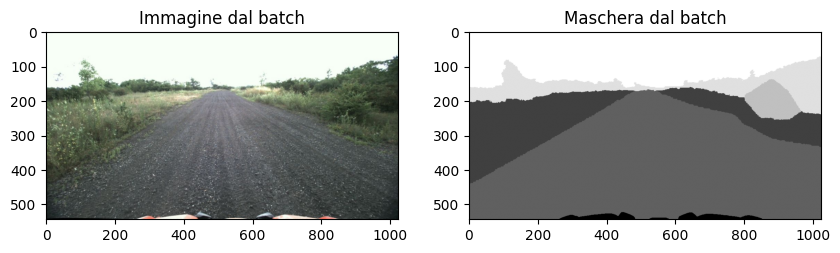

In [10]:
# --- ESEMPIO DI UTILIZZO ---

def segmentationDataset_test(train_loader):
  # Prendiamo un batch dal train_loader per vedere come funziona
  images_batch, masks_batch = next(iter(train_loader))

  print(f"Forma del batch di immagini: {images_batch.shape}") # Dovrebbe essere [batch_size, 3, H, W]
  print(f"Forma del batch di maschere: {masks_batch.shape}") # Dovrebbe essere [batch_size, 1, H, W]

  # Visualizziamo la prima immagine e maschera del batch
  plt.figure(figsize=(10, 5))
  plt.subplot(1, 2, 1)
  plt.imshow(images_batch[0].permute(1, 2, 0)) # Rimetto in formato H, W, C
  plt.title("Immagine dal batch")

  plt.subplot(1, 2, 2)
  plt.imshow(masks_batch[0].squeeze(), cmap='gray')
  plt.title("Maschera dal batch")
  plt.show()



if not EXECUTE_MAIN:
  segmentationDataset_test(train_loader)

# Calcolo della distribuzione del dataset



Trovati 931 campioni totali validi.


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:15<00:00,  1.03s/it]



Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


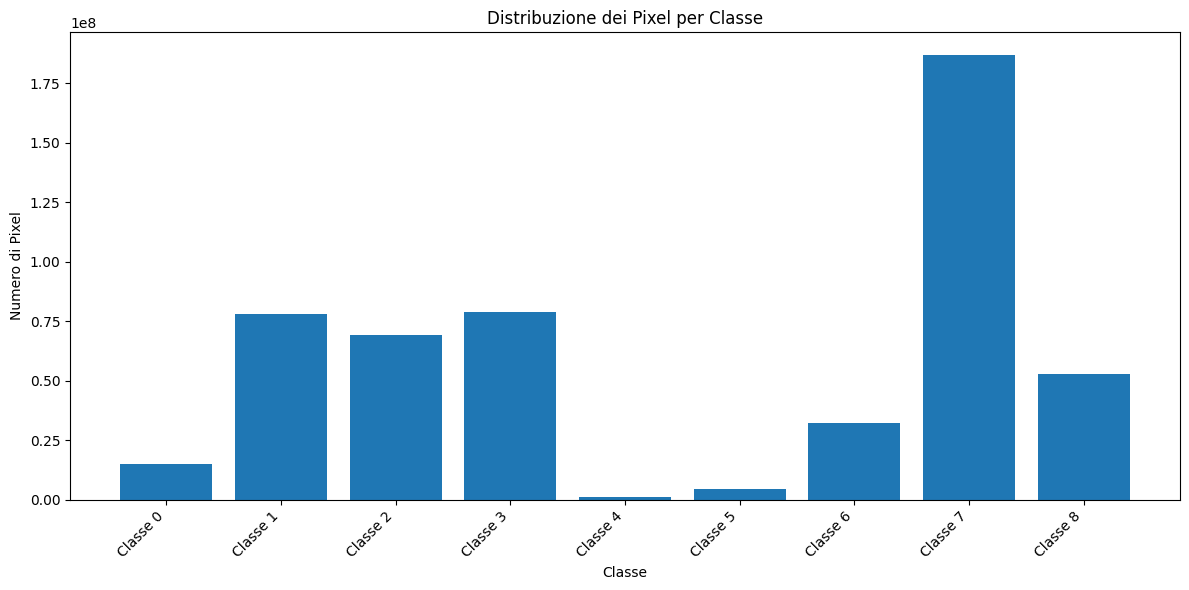

In [16]:
def calculate_class_distribution_gpu(dataset, device):
  """
  Calcola il numero di pixel per ogni classe, usando la GPU se disponibile.
  """
  num_classes = 9 # Da 0 a 8

  class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)

  loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)

  for _, masks_batch in tqdm(loader, desc="Analisi distribuzione classi (GPU)"):
    masks_batch = masks_batch.to(device)

    for i in range(masks_batch.shape[0]):
      mask = masks_batch[i]
      class_counts += torch.bincount(mask.flatten(), minlength=num_classes)

  # sulla CPU per NumPy e Matplotlib
  return class_counts.cpu()


def distribution_analysis(full_dataset, class_names):
  # Calcoliamo la distribuzione
  distribution = calculate_class_distribution_gpu(full_dataset, device)

  # Stampiamo e visualizziamo i risultati
  total_pixels = distribution.sum()
  print("\nDistribuzione delle classi nel dataset:")
  for i, count in enumerate(distribution):
    percentage = 100 * count.float() / total_pixels
    print(f"- Classe '{class_names[i]}' ({i}): {count} pixel ({percentage:.2f}%)")

  plt.figure(figsize=(12, 6))
  plt.bar(class_names, distribution.numpy())
  plt.xlabel("Classe")
  plt.ylabel("Numero di Pixel")
  plt.title("Distribuzione dei Pixel per Classe")
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()


if not EXECUTE_MAIN:
  # Creiamo un dataset con tutti i campioni ...
  all_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
  # ... senza __MACOSX
  all_sample_dirs = [d for d in all_sample_dirs if not os.path.basename(d).startswith('__')]
  print(f"Trovati {len(all_sample_dirs)} campioni totali validi.")

  full_dataset = SegmentationDataset(sample_dirs=all_sample_dirs)

  class_names = []
  for idx in range(9):
    class_names.append(f"Classe {idx}")

  distribution_analysis(full_dataset, class_names)

# Conclusions
---
_it_

Le classi **non sono bilanciate**. La classe 7 rappresenta il **36%**, un valore altissimo.

Questa situazione è **problematica** perché bisogna attuare delle contromisure che spingano il modello a colmare questo gap e diano omogeneità nell'apprendimento, altrimenti si *rischia che la rete ignori completamente le altri classi ed apprenda solo la predominante*.

Per garantire un apprendimento migliore, possiamo utilizzare la data augmentation e cercare una metrica di loss che minimizzi la cross-entropy-loss e attenui lo sbilanciamento delle classi presentie nella realtà di interesse.

L'analisi della distribuzione ci consiglia di non fidarci della sola *accuratezza*. Ci conviene usare il *mean Intersection-over-Union* (IoU), già usata nel contest. Questa metrica ci permette di comprendere quanti pixel riconosce correttamente la rete sia totali che per singola classe. Questo ci consente di poter anche classificare le metriche di loss.

---
_en_:



# Co Occurrence Matrix

Analisi Co-occorrenza: 100%|██████████| 931/931 [00:29<00:00, 31.22it/s]


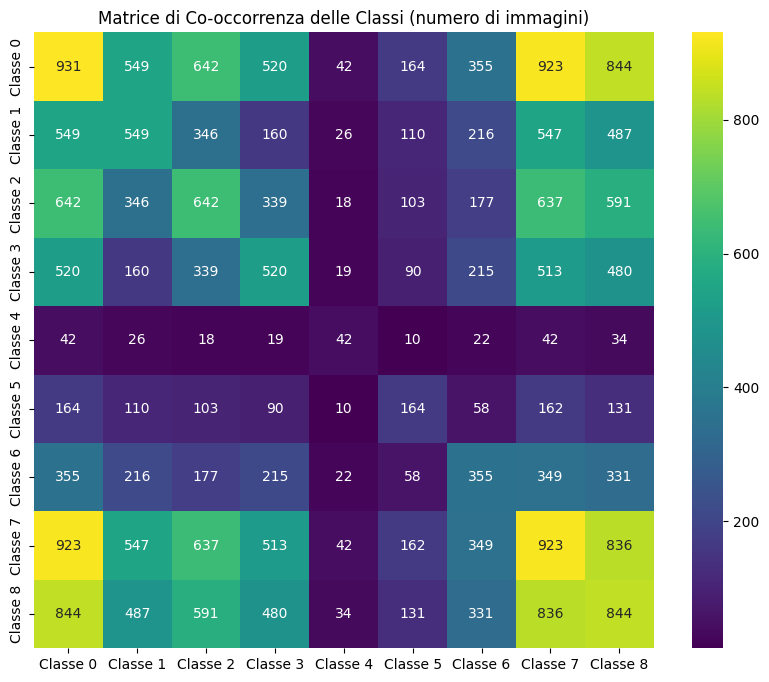

In [17]:
import seaborn as sns

def calculate_co_occurrence(dataset, num_classes):
    co_occurrence_matrix = torch.zeros((num_classes, num_classes), dtype=torch.int64)

    for _, mask in tqdm(dataset, desc="Analisi Co-occorrenza"):
        # Trova le classi uniche presenti in questa maschera
        unique_classes_in_mask = torch.unique(mask)

        # Per ogni coppia di classi uniche, incrementa la matrice
        for i in range(len(unique_classes_in_mask)):
            for j in range(i, len(unique_classes_in_mask)):
                class1 = unique_classes_in_mask[i]
                class2 = unique_classes_in_mask[j]
                # La matrice è simmetrica
                co_occurrence_matrix[class1, class2] += 1
                if class1 != class2:
                    co_occurrence_matrix[class2, class1] += 1

    return co_occurrence_matrix


def co_occurance_analysis(full_dataset, class_names):
  # Calcoliamo la matrice sul dataset completo
  co_occurrence_matrix = calculate_co_occurrence(full_dataset, num_classes=9)

  # Visualizziamo con una heatmap per una migliore leggibilità
  plt.figure(figsize=(10, 8))
  sns.heatmap(co_occurrence_matrix.numpy(), annot=True, fmt='d', cmap='viridis',
              xticklabels=class_names, yticklabels=class_names)
  plt.title("Matrice di Co-occorrenza delle Classi (numero di immagini)")
  plt.show()

if not EXECUTE_MAIN:
  co_occurance_analysis(full_dataset, class_names)

In [18]:

def main():
  train_loader, val_loader = split_dataset(DATASET_PATH)

  segmentationDataset_test(train_loader)

  # Creiamo un dataset con tutti i campioni ...
  all_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
  # ... senza __MACOSX
  all_sample_dirs = [d for d in all_sample_dirs if not os.path.basename(d).startswith('__')]
  print(f"Trovati {len(all_sample_dirs)} campioni totali validi.")

  full_dataset = SegmentationDataset(sample_dirs=all_sample_dirs)

  class_names = []
  for idx in range(9):
    class_names.append(f"Classe {idx}")

  distribution_analysis(full_dataset, class_names)
  co_occurance_analysis(full_dataset, class_names)


if __name__ == "main":
  if EXECUTE_MAIN:
    main()

# Conclusions
---
_it_:

Utilizzando la matrice di co occorenza notiamo che:


*   *Puddle*, *background* ed *obstacle* compaiono molto spesso insieme, probabilmente, puddle non è solo una semplice pozzanghera
*   List item



In [19]:
import torch
from tqdm import tqdm
import os

def get_representative_images_per_class(dataset, num_classes, class_names, top_n=5):
    """
    Analizza il dataset per trovare le 'top_n' immagini più rappresentative per ogni classe.

    Args:
        dataset (Dataset): L'istanza del dataset completo.
        num_classes (int): Il numero di classi totali.
        class_names (list): La lista dei nomi delle classi.
        top_n (int): Il numero di immagini da mostrare per ogni classe.
    """
    print(f"Inizio analisi per trovare le {top_n} immagini più rappresentative per classe...")

    class_images = [[] for _ in range(num_classes)]

    for i in tqdm(range(len(dataset)), desc="Analisi Immagini"):
        _, mask = dataset[i]
        total_pixels_in_mask = mask.numel()
        if total_pixels_in_mask == 0:
            continue
        counts = torch.bincount(mask.flatten(), minlength=num_classes)
        for class_id in range(num_classes):
            if counts[class_id] > 0:
                percentage = 100.0 * counts[class_id] / total_pixels_in_mask
                sample_path = dataset.sample_dirs[i]
                class_images[class_id].append((percentage, sample_path))

    print("\nAnalisi completata. Ordino e stampo i risultati...")

    # Ordinamento e Stampa
    for class_id in range(num_classes):
        print("-" * 50)
        print(f"CLASSE: {class_names[class_id].upper()} ({class_id})")
        print("-" * 50)

        sorted_images = sorted(class_images[class_id], key=lambda x: x[0], reverse=True)

        if not sorted_images:
            print("Nessuna immagine trovata per questa classe.")
            continue

        # Stampa solo i primi 'top_n' elementi
        for idx, (percentage, path) in enumerate(sorted_images[:top_n]):
            print(f"{idx + 1}. {os.path.basename(path)} (presenza: {percentage:.2f}%)")



print("--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---")
get_representative_images_per_class(full_dataset, num_classes=9, class_names=class_names, top_n=1)



--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---
Inizio analisi per trovare le 1 immagini più rappresentative per classe...


Analisi Immagini:   0%|          | 0/931 [00:00<?, ?it/s]

Analisi Immagini: 100%|██████████| 931/931 [00:10<00:00, 89.34it/s]



Analisi completata. Ordino e stampo i risultati...
--------------------------------------------------
CLASSE: CLASSE 0 (0)
--------------------------------------------------
1. 0546 (presenza: 44.05%)
--------------------------------------------------
CLASSE: CLASSE 1 (1)
--------------------------------------------------
1. 0312 (presenza: 66.15%)
--------------------------------------------------
CLASSE: CLASSE 2 (2)
--------------------------------------------------
1. 0833 (presenza: 73.56%)
--------------------------------------------------
CLASSE: CLASSE 3 (3)
--------------------------------------------------
1. 1147 (presenza: 66.82%)
--------------------------------------------------
CLASSE: CLASSE 4 (4)
--------------------------------------------------
1. 0305 (presenza: 19.65%)
--------------------------------------------------
CLASSE: CLASSE 5 (5)
--------------------------------------------------
1. 0531 (presenza: 39.47%)
------------------------------------------------

class 0


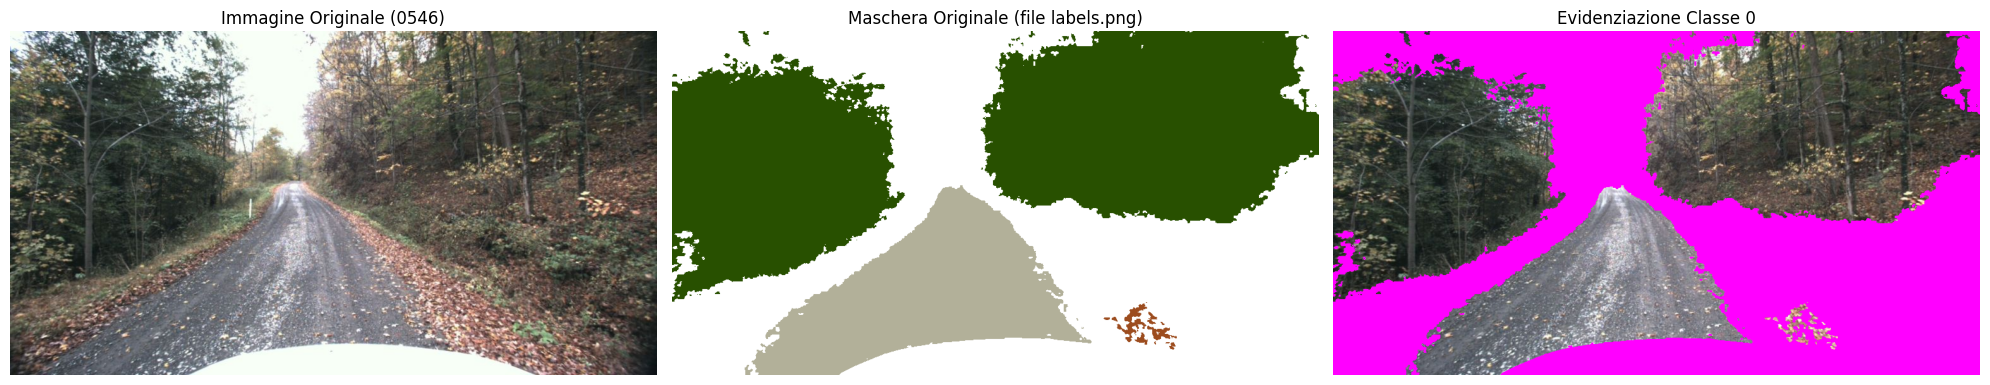

class 1


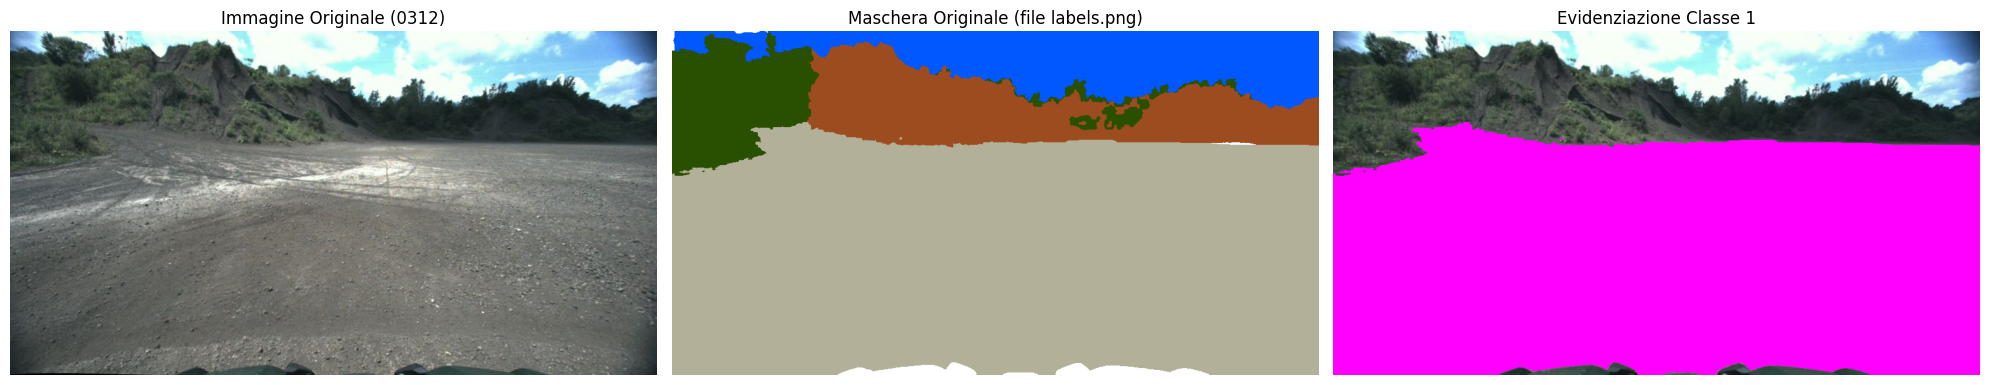

class 2


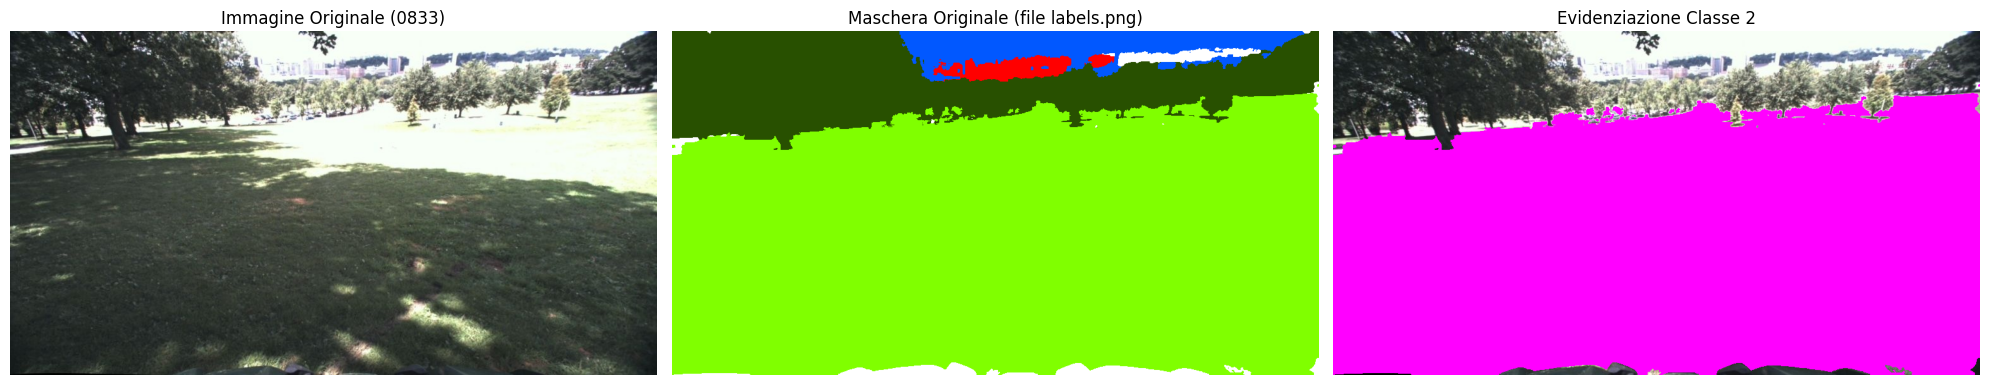

class 3


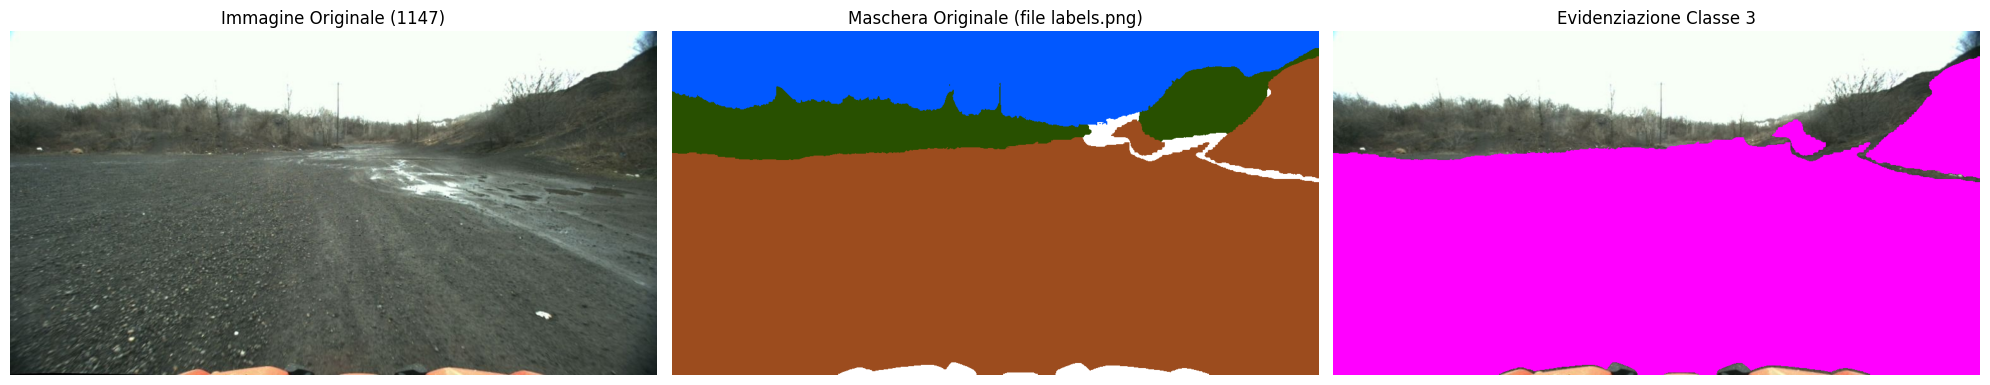

class 4


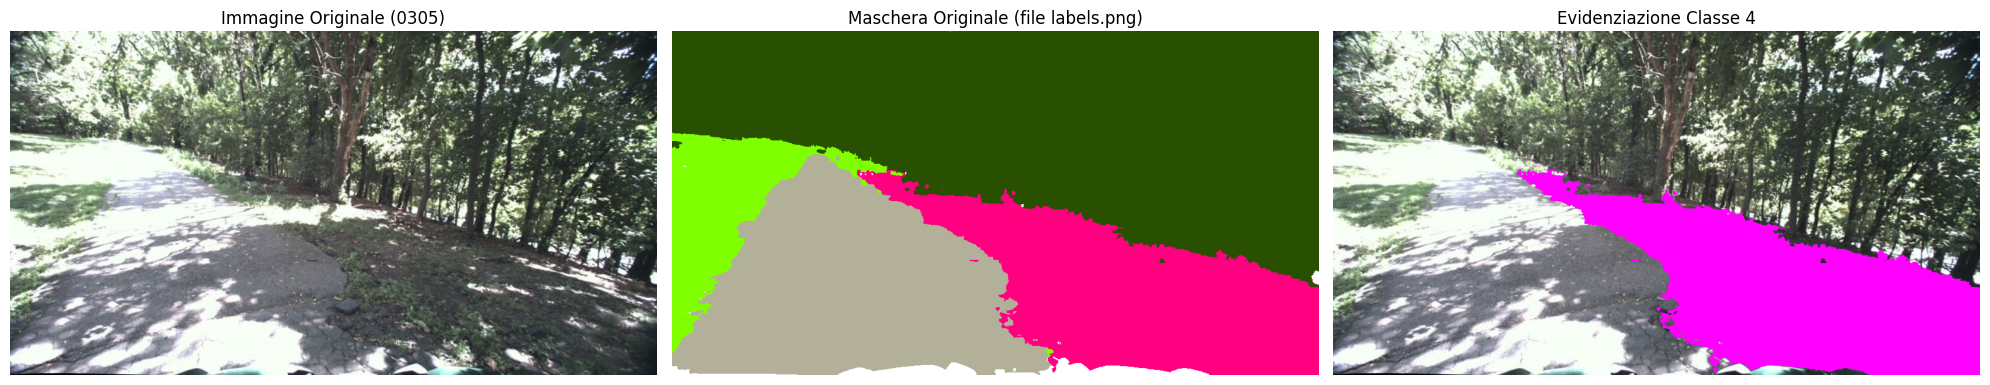

class 5


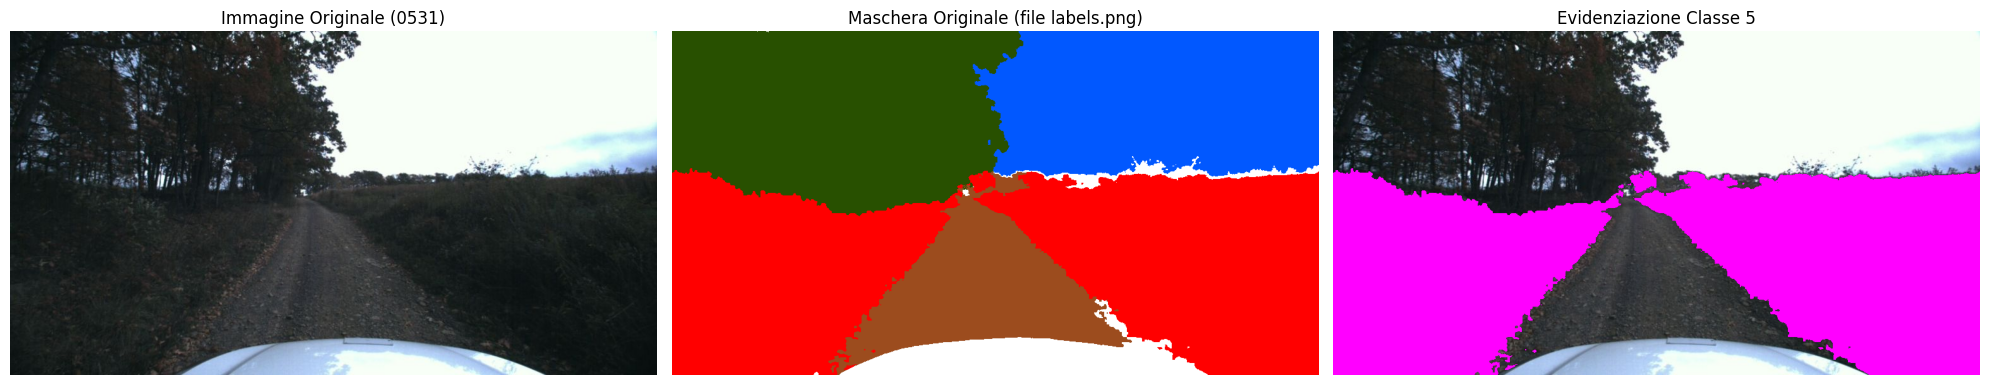

class 6


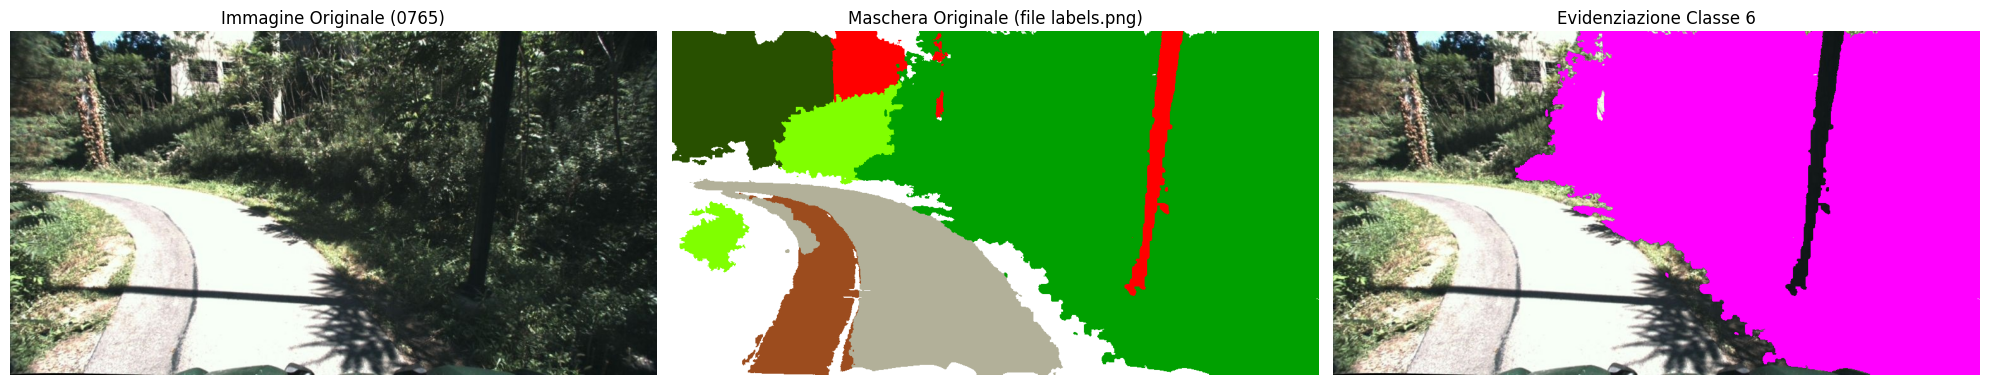

class 7


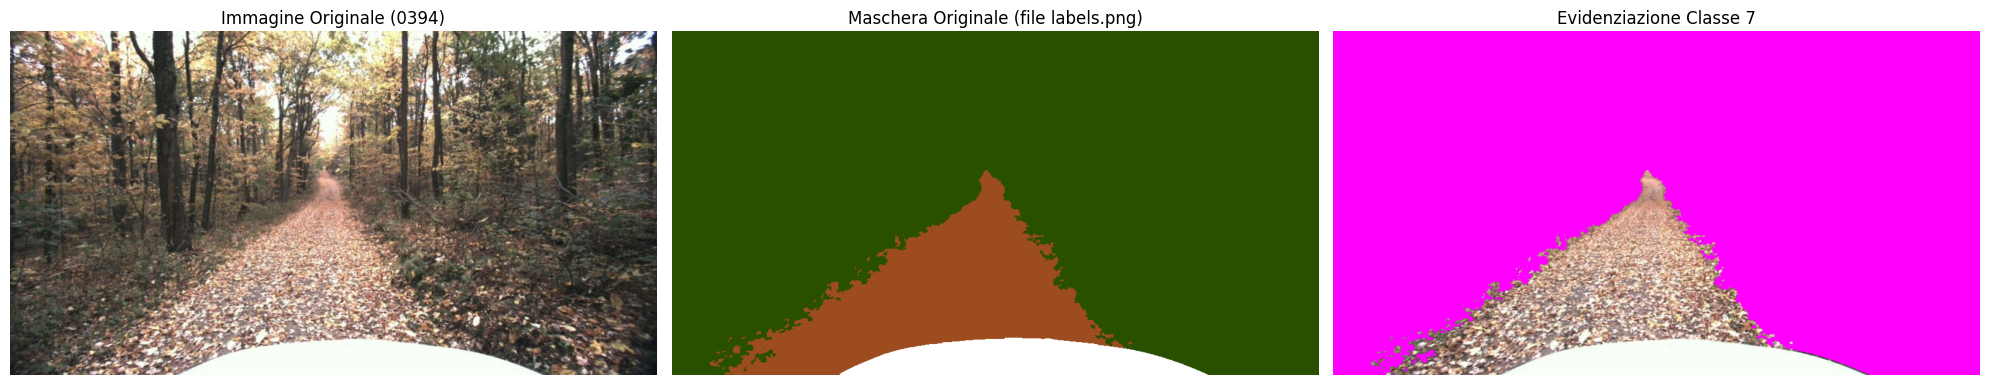

class 8


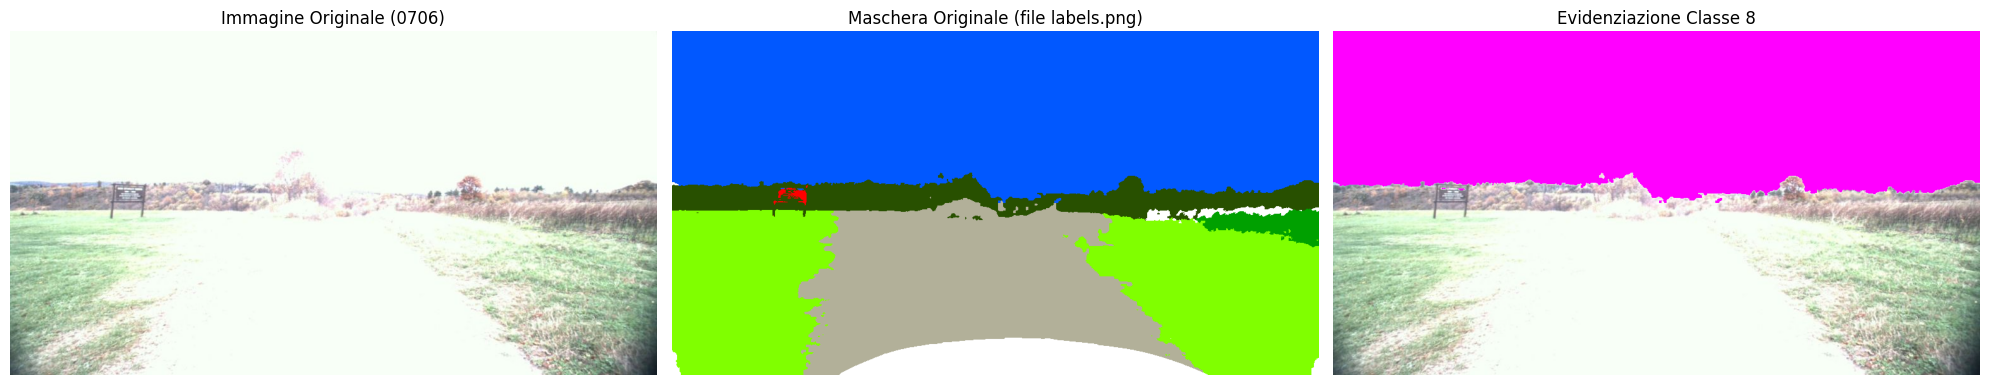

In [20]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os

def highlight_class_in_image_simple(sample_dir_path, class_id_to_highlight, highlight_color=[255, 0, 255]):
    """
    Carica un'immagine, la sua maschera originale (come file), e crea una versione
    evidenziata per una classe specifica.

    Args:
        sample_dir_path (string): Il percorso completo alla cartella del campione (es. '.../train/0546').
        class_id_to_highlight (int): L'ID della classe da evidenziare.
        highlight_color (list): Il colore RGB per l'evidenziazione.
    """

    img_path = os.path.join(sample_dir_path, 'rgb.jpg')
    mask_path = os.path.join(sample_dir_path, 'labels.png')

    try:
        # 1. Carica l'immagine originale e la maschera come file immagine
        original_image = Image.open(img_path)
        original_mask_image = Image.open(mask_path)

        # 2. Crea l'immagine evidenziata
        # Per farlo, dobbiamo comunque leggere la maschera come array di indici
        mask_np = np.array(original_mask_image) # Questo legge gli indici (0-8)

        highlighted_image = np.array(original_image).copy()
        pixels_to_highlight = (mask_np == class_id_to_highlight)
        highlighted_image[pixels_to_highlight] = highlight_color

    except FileNotFoundError:
        print(f"Errore: file non trovati nel percorso {sample_dir_path}")
        return

    # 3. Visualizza tutto
    sample_name = os.path.basename(sample_dir_path)

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(original_image)
    plt.title(f"Immagine Originale ({sample_name})")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(original_mask_image)
    plt.title("Maschera Originale (file labels.png)")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(highlighted_image)
    plt.title(f"Evidenziazione Classe {class_id_to_highlight}")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# --- Esempio di utilizzo ---
# NOTA: Ora passiamo direttamente il percorso della cartella, non l'indice.

# Percorso alla cartella del campione

images = ["0546","0312", "0833","1147","0305","0531","0765","0394", "0706"]

for idx, image in enumerate(images):
  print(f"class {idx}")
  path = os.path.join(DATASET_PATH, image)
  highlight_class_in_image_simple(path, class_id_to_highlight=idx)


sky: 8
rough trail: 3
smooth trail: 1
traversable grass: 2
high vegetation: 7
non-traversable: 5
low vegetation: 6
puddle:
obstacle:
background: 0


4